# 03. 고장 이벤트·고장 전 시계열·TTF 검증

모든 fault 이력과 TTF는 분석용 정답으로만 사용합니다. 고장 이후 데이터나 TTF를 예측 특징으로 만들지 않으며 모델 학습은 수행하지 않습니다. 대표 장비는 01M01로 고정하고, 이벤트는 센서 변화 크기가 아닌 **관측 충분성**으로 선정합니다.

시간 단위는 미확정이므로 5·10·30·60분 표시는 **time=초 가정**입니다. 분석 구간은 각각 300·600·1800·3600 원시시간 단위이며 고장 시각 자체는 제외합니다.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd()/"src").is_dir() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
assert Path(sys.prefix).name.lower()=="phm2018", sys.executable
assert sys.version_info[:2]==(3,11), sys.version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.eda_common import DATA, OUT, SENSORS, FAULTS, SOURCE_URL, overview, read_json, load_faults, snapshot
from src.eda_detail import representative, audit_time_keys, audit_tagged_ttf, horizon_labels
from src import eda_plots as plots
plots.setup()
pd.set_option("display.max_columns",30)
pd.set_option("display.max_rows",80)
print("실행 Python:",sys.executable)
print("Python 버전:",sys.version.split()[0])

실행 Python: C:\Users\fl27\anaconda3\envs\phm2018\python.exe
Python 버전: 3.11.18


In [2]:
result=overview();detail=representative();faults=load_faults()
unique_faults=faults.drop_duplicates(["Tool","time","fault_raw"]).copy()
keys=audit_time_keys()
tag_audit=audit_tagged_ttf()
alignment=pd.DataFrame(result["fault_alignment"])
ttf=pd.DataFrame(result["ttf"])
display(pd.DataFrame(keys["files"])[["file","sensor_rows","ttf_rows","ordered_time_keys_equal"]])
assert all(x["ordered_time_keys_equal"] for x in keys["files"])
print("fault 중복 이벤트 행:",result["fault_duplicates"])

검증된 입력/코드 메타데이터와 일치하는 로컬 집계 캐시 사용


대표 장비의 검증된 로컬 집계 캐시 사용


,file,sensor_rows,ttf_rows,ordered_time_keys_equal
0,01_M01_DC_train.csv,3124704,3124704,True
1,01_M02_DC_train.csv,5110542,5110542,True
2,02_M01_DC_train.csv,2865625,2865625,True
3,02_M02_DC_train.csv,4143973,4143973,True
4,03_M01_DC_train.csv,3432217,3432217,True
5,03_M02_DC_train.csv,5060498,5060498,True
6,04_M01_DC_train.csv,5097901,5097901,True
7,04_M02_DC_train.csv,4450348,4450348,True
8,05_M01_DC_train.csv,4779554,4779554,True
9,05_M02_DC_train.csv,1907102,1907102,True


fault 중복 이벤트 행: 25


## 고장 유형과 장비별 발생 횟수

원문 이름과 정규화 이름을 함께 제공합니다. 동일 `(Tool,time,fault_raw)` 중복 25행을 제외한 고유 이벤트 수와 원본 이력 행 수를 구분합니다. `[NoWaferID]`는 표기 태그로 분리하여 3종 분포에 포함하되, TTF 의미 검증에서는 포함/제외를 모두 비교합니다. 단위 기간당 고장률은 아닙니다.

,원문 이벤트 수
FlowCool Pressure Dropped Below Limit,756
Flowcool Pressure Too High Check Flowcool Pump,340
Flowcool leak,139
Flowcool Pressure Too High Check Flowcool Pump [NoWaferID],1


,3종 집계 이벤트 수
FlowCool Pressure Dropped Below Limit,756
Flowcool Pressure Too High Check Flowcool Pump,341
Flowcool leak,139


,원본 이력 행 수,고유 이벤트 수
fault_name,,
FlowCool Pressure Dropped Below Limit,756,741
Flowcool Pressure Too High Check Flowcool Pump,341,333
Flowcool leak,139,137


fault_name,FlowCool Pressure Dropped Below Limit,Flowcool Pressure Too High Check Flowcool Pump,Flowcool leak
Tool,,,
01M01,13,5,1
01M02,53,40,16
02M01,9,7,1
02M02,5,27,0
03M01,40,51,0
03M02,298,49,9
04M01,7,1,1
04M02,21,1,15
05M01,14,7,7


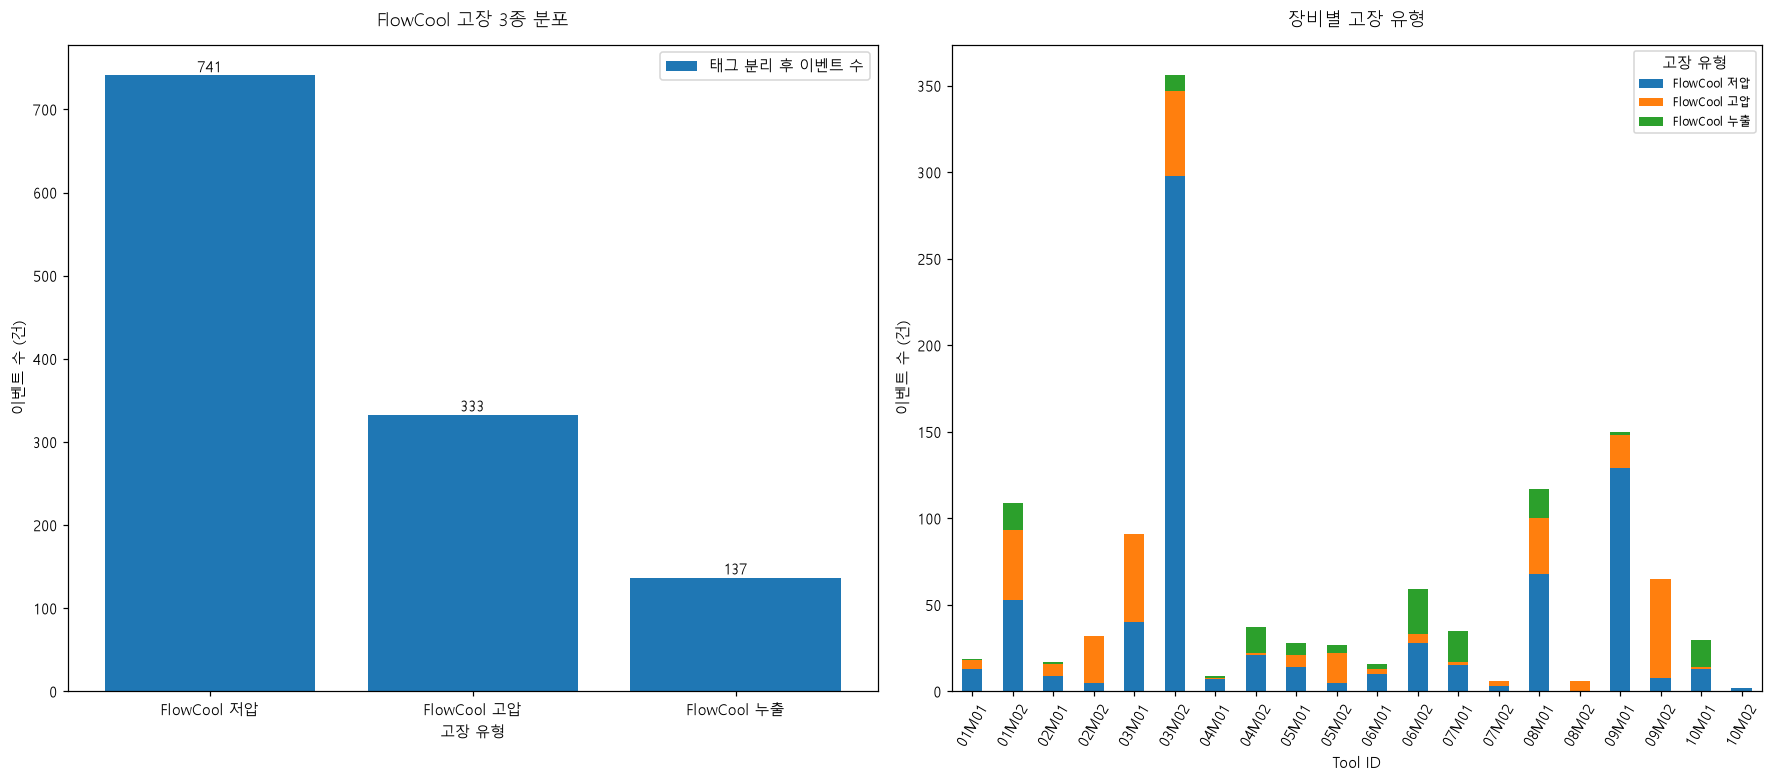

원본 고장 이력은 **1,236행**, 동일 장비·시각·원문 고장 유형을 중복 제거한 이벤트는 **1,211건**입니다. 고유 이벤트는 저압 741건, 고압 333건(태그 1건 포함), 누출 137건입니다. 원본 파일은 변경하지 않았습니다. 장비별 노출 시간과 관측 공백이 다르므로 이 건수만으로 신뢰성을 비교하지 않습니다.

In [3]:
display(pd.Series(result["fault_raw_counts"],name="원문 이벤트 수").to_frame())
display(pd.Series(result["fault_counts"],name="3종 집계 이벤트 수").to_frame())
count_comparison=pd.DataFrame({"원본 이력 행 수":faults.fault_name.value_counts(),"고유 이벤트 수":unique_faults.fault_name.value_counts()})
display(count_comparison)
display(pd.crosstab(unique_faults.Tool,unique_faults.fault_name))
plots.fault_distribution(unique_faults)
display(Markdown(f"원본 고장 이력은 **{len(faults):,}행**, 동일 장비·시각·원문 고장 유형을 중복 제거한 이벤트는 **{len(unique_faults):,}건**입니다. 고유 이벤트는 저압 741건, 고압 333건(태그 1건 포함), 누출 137건입니다. 원본 파일은 변경하지 않았습니다. 장비별 노출 시간과 관측 공백이 다르므로 이 건수만으로 신뢰성을 비교하지 않습니다."))

## Fault와 센서의 연결 기준 및 시간 정합성

파일 접두어로 후보 장비를 찾은 뒤 실제 `Tool`을 확인하고 시각을 비교합니다. `(Tool,time)`은 센서에서 비고유하므로 센서 행 식별자와 고장 이벤트 ID를 구분합니다. 행 번호로 fault를 붙이지 않습니다. 정확한 시각 일치뿐 아니라 가장 가까운 엄격한 이전/이후 관측을 전 청크에 걸쳐 추적했습니다.

In [4]:
tool_table=pd.DataFrame(result["tools"])
train_info=tool_table[tool_table.split=="train"].set_index("Tool")
alignment["inside_sensor_range"]=[train_info.loc[x.Tool,"min_time"]<=x.fault_time<=train_info.loc[x.Tool,"max_time"] for x in alignment.itertuples()]
alignment=alignment[alignment.event_id.isin(unique_faults.event_id)].copy()
display(alignment.groupby("Tool").agg(고장수=("event_id","size"),정확일치수=("exact_rows",lambda x:int((x>0).sum())),측정범위내=("inside_sensor_range","sum")))
display(alignment[["previous_gap_raw","next_gap_raw"]].replace([np.inf,-np.inf],np.nan).describe())
finite_previous=alignment.previous_gap_raw[np.isfinite(alignment.previous_gap_raw)]
display(Markdown(f"정확히 센서 시각과 일치하는 이벤트는 **{int((alignment.exact_rows>0).sum())}/{len(alignment)}건**입니다. 측정 범위 밖 이벤트는 **{int((~alignment.inside_sensor_range).sum())}건**입니다. 직전 관측까지의 간격은 결측·무한대를 제외한 중앙값 **{finite_previous.median():g} 원시시간 단위**입니다. 정확 일치가 없는 이벤트를 임의로 가장 가까운 센서 행의 고장으로 덮어쓰지 않습니다. 아래 윈도별 관측 충분성으로 분석 가능 여부를 판정합니다."))

,고장수,정확일치수,측정범위내
Tool,,,
01M01,19,8,19
01M02,109,36,109
02M01,17,5,17
02M02,32,3,32
03M01,91,7,91
03M02,356,23,356
04M01,9,3,9
04M02,37,13,36
05M01,28,8,28


,previous_gap_raw,next_gap_raw
count,1207.000000,1211.000000
mean,25983.663629,13585.535921
std,69124.516242,42816.774309
min,2.000000,2.000000
25%,4.000000,4.000000
50%,1450.000000,1316.000000
75%,12863.000000,2278.000000
max,629868.000000,590478.000000


정확히 센서 시각과 일치하는 이벤트는 **211/1211건**입니다. 측정 범위 밖 이벤트는 **4건**입니다. 직전 관측까지의 간격은 결측·무한대를 제외한 중앙값 **1450 원시시간 단위**입니다. 정확 일치가 없는 이벤트를 임의로 가장 가까운 센서 행의 고장으로 덮어쓰지 않습니다. 아래 윈도별 관측 충분성으로 분석 가능 여부를 판정합니다.

## 고장 전 5·10·30·60분: 관측 충분성 우선

최빈 양의 간격(4 원시단위)을 기준으로 고유 시각 수/기대 관측 수가 90% 이상이고, 양 끝 공백이 2간격 이하, 내부 최대 공백이 3간격 이하인 경우만 충분하다고 표시합니다. 동일 시각의 중복 행은 원본대로 유지하되 충분성 분자에는 고유 시각 수만 사용합니다. 01M01의 모든 이벤트를 확인한 뒤 충분한 윈도 수가 가장 많은 이벤트, 동률이면 더 이른 이벤트를 선택합니다. 이는 초기 사례 분석이며 고장 유형 전체의 대표성은 보장하지 않습니다.

,event_id,fault_name,time,stage>0 비율,rows,unique_times,expected_at_mode,coverage_ratio,start_gap,end_gap,max_gap,sufficient,minutes_assuming_seconds
0,0,FlowCool Pressure Dropped Below Limit,6533184.0,1.0,49,49,75.0,0.653333,104.0,4.0,4.0,False,5
1,0,FlowCool Pressure Dropped Below Limit,6533184.0,1.0,49,49,150.0,0.326667,404.0,4.0,4.0,False,10
2,0,FlowCool Pressure Dropped Below Limit,6533184.0,1.0,219,219,450.0,0.486667,0.0,4.0,928.0,False,30
3,0,FlowCool Pressure Dropped Below Limit,6533184.0,1.0,432,432,900.0,0.480000,0.0,4.0,928.0,False,60
4,1,FlowCool Pressure Dropped Below Limit,8286500.0,1.0,23,23,75.0,0.306667,208.0,4.0,4.0,False,5
5,1,FlowCool Pressure Dropped Below Limit,8286500.0,1.0,23,23,150.0,0.153333,508.0,4.0,4.0,False,10
6,1,FlowCool Pressure Dropped Below Limit,8286500.0,1.0,267,267,450.0,0.593333,0.0,4.0,736.0,False,30
7,1,FlowCool Pressure Dropped Below Limit,8286500.0,1.0,660,660,900.0,0.733333,0.0,4.0,736.0,False,60
8,2,FlowCool Pressure Dropped Below Limit,8627086.0,1.0,74,63,75.0,0.840000,0.0,4.0,74.0,False,5
9,2,FlowCool Pressure Dropped Below Limit,8627086.0,1.0,122,111,150.0,0.740000,0.0,4.0,112.0,False,10


,rows,unique_times,expected_at_mode,coverage_ratio,start_gap,end_gap,max_gap,sufficient,minutes_assuming_seconds
0,75,75,75.0,1,2.0,2.0,6.0,True,5
1,150,150,150.0,1,2.0,2.0,6.0,True,10
2,450,450,450.0,1,2.0,2.0,6.0,True,30
3,900,900,900.0,1,2.0,2.0,6.0,True,60


,start,end,rows,unique_times,expected_at_mode,coverage_ratio,start_gap,end_gap,max_gap,sufficient
0,26088148.0,26091748.0,900,900,900.0,1,2.0,2.0,4.0,True


선택 이벤트: 11 Flowcool Pressure Too High Check Flowcool Pump time= 26098948.0


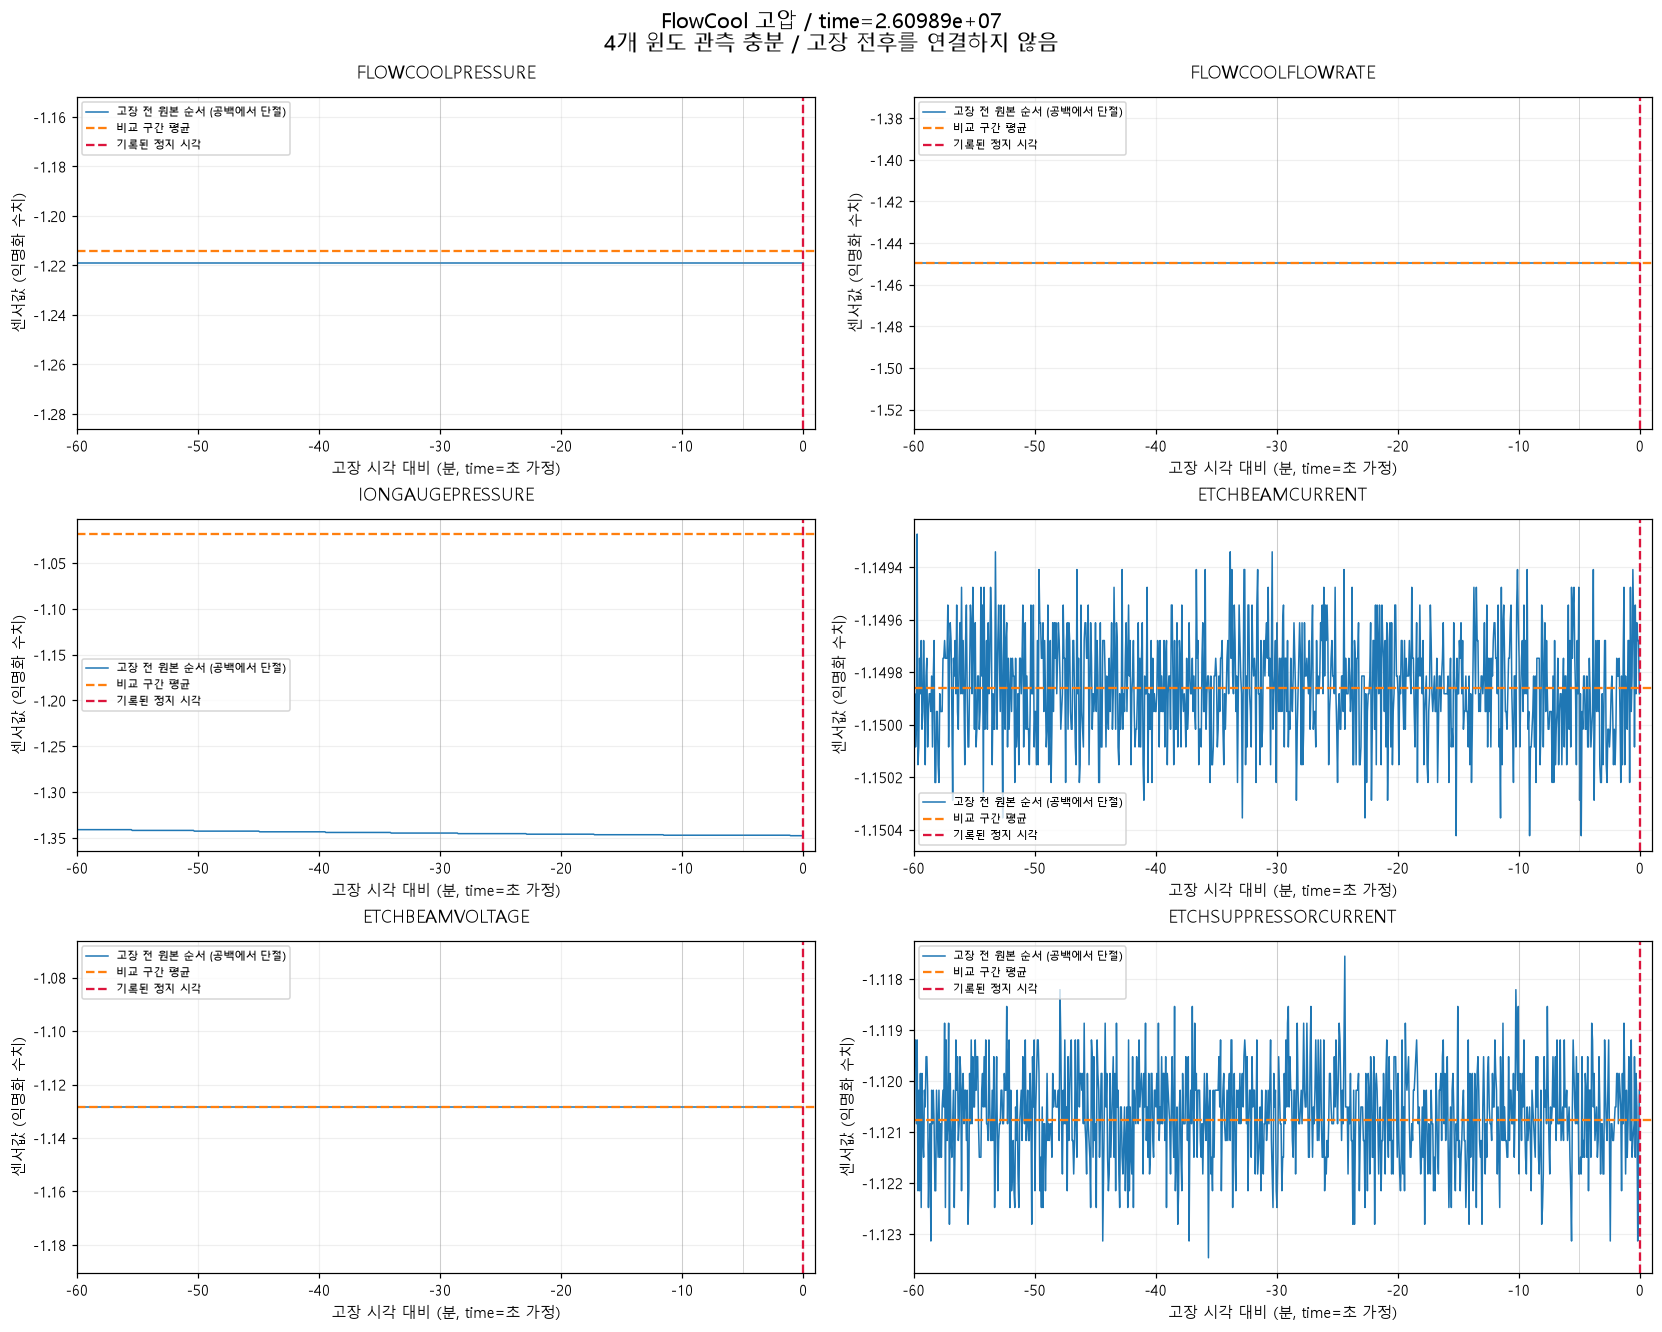

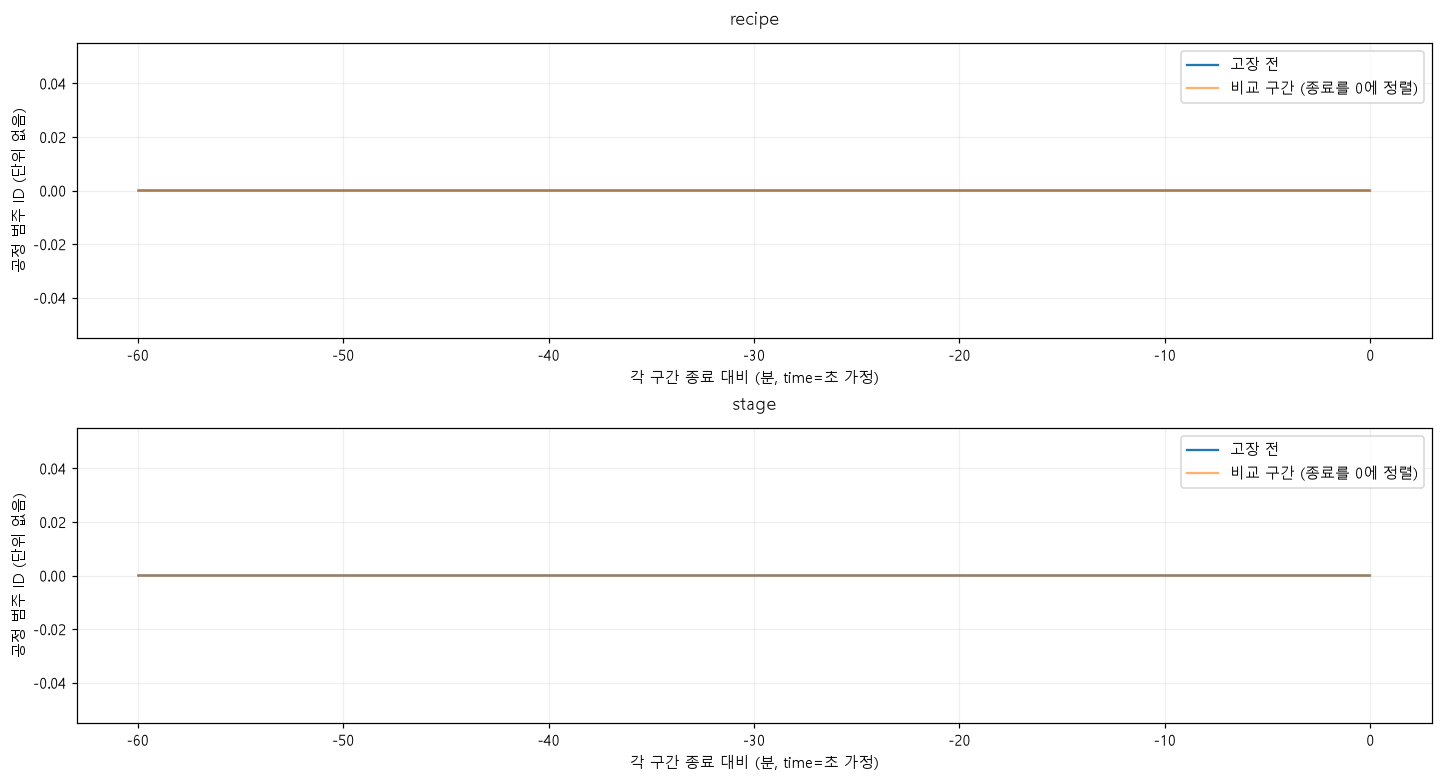

In [5]:
candidate_rows=[]
for e in detail["event_candidates"]:
    for w in e["windows"]:candidate_rows.append({"event_id":e["event_id"],"fault_name":e["fault_name"],"time":e["time"],"stage>0 비율":e["stage_nonzero_ratio"],**w})
display(pd.DataFrame(candidate_rows))
event=detail["selected_event"]
pre=pd.read_json(OUT/"pre_event.json");control=pd.read_json(OUT/"control.json")
display(pd.DataFrame(event["windows"]))
display(pd.DataFrame([detail["control"]]))
print("선택 이벤트:",event["event_id"],event["fault_name"],"time=",event["time"])
plots.event_plot(pre,event,control,note="4개 윈도 관측 충분 / 고장 전후를 연결하지 않음")
plots.process_timeline(pre,control,event)

## 비교 구간과 공정 조건 통제

비교 후보는 같은 장비에서 선택 이벤트보다 과거이며 모든 알려진 fault에서 3600 원시시간 단위 이상 떨어진 구간입니다. **무고장 상태가 보장된 정상 정답이 아닙니다.** 공정이 진행 중인지도 Stage/Recipe와 함께 검토합니다. 두 구간의 동일 Recipe/Stage 조합에 각각 10개 이상 유효 관측이 있을 때만 조건별 비교 가능으로 표시합니다.

In [6]:
display(pd.DataFrame(detail["comparisons"]))
display(pre.groupby(["recipe","stage"]).size().rename("고장 전 행 수").to_frame())
display(control.groupby(["recipe","stage"]).size().rename("비교 구간 행 수").to_frame())
display(pd.DataFrame(detail["matched_comparisons"]))
hour=pd.DataFrame(detail["comparisons"]).query("minutes_assuming_seconds==60").set_index("sensor")
first=pre[pre.time<event["time"]-1800];last=pre[pre.time>=event["time"]-1800]
within=pd.DataFrame({"앞 30분 평균":first[SENSORS].mean(),"뒤 30분 평균":last[SENSORS].mean()})
within["뒤-앞"]=within["뒤 30분 평균"]-within["앞 30분 평균"]
display(within)
display(Markdown(f"선택 이벤트와 비교 구간은 모두 **Recipe=0, Stage=0**입니다. 가동 중 정상 운전이라고 확인할 수 없는 상태입니다. IONGAUGEPRESSURE의 60분 평균 차이는 **{hour.loc['IONGAUGEPRESSURE','difference']:.4f}**이고, 고장 전 구간 내부 앞/뒤 30분 차이는 **{within.loc['IONGAUGEPRESSURE','뒤-앞']:.4f}**입니다. FLOWCOOLPRESSURE는 고장 전 구간에서 일정하고 비교 구간과의 평균 차이는 **{hour.loc['FLOWCOOLPRESSURE','difference']:.4f}**입니다. 이 한 사례에서는 고압 고장으로 가는 압력 상승 전조를 확인하지 못했습니다. 구간 간 차이와 고장 직전의 진행성 변화를 구분해야 합니다."))

,minutes_assuming_seconds,sensor,pre_mean,pre_std,control_mean,difference,window_sufficient,control_sufficient
0,5,FLOWCOOLPRESSURE,-1.218926,2.235399e-16,-1.214030,-4.895427e-03,True,True
1,5,FLOWCOOLFLOWRATE,-1.449477,2.235399e-16,-1.449477,-2.220446e-16,True,True
2,5,IONGAUGEPRESSURE,-1.347226,2.133911e-04,-1.018377,-3.288492e-01,True,True
3,5,ETCHBEAMCURRENT,-1.149916,2.180503e-04,-1.149859,-5.637864e-05,True,True
4,5,ETCHBEAMVOLTAGE,-1.128402,4.470797e-16,-1.128402,0.000000e+00,True,True
5,5,ETCHSUPPRESSORCURRENT,-1.120702,9.208957e-04,-1.120761,5.873004e-05,True,True
6,10,FLOWCOOLPRESSURE,-1.218926,2.227885e-16,-1.214030,-4.895427e-03,True,True
7,10,FLOWCOOLFLOWRATE,-1.449477,2.227885e-16,-1.449477,-2.220446e-16,True,True
8,10,IONGAUGEPRESSURE,-1.347171,1.602546e-04,-1.018377,-3.287940e-01,True,True
9,10,ETCHBEAMCURRENT,-1.149896,2.148423e-04,-1.149859,-3.700998e-05,True,True


,,고장 전 행 수
recipe,stage,
0,0,900


,,비교 구간 행 수
recipe,stage,
0,0,900


,recipe,stage,sensor,pre_n,control_n,pre_mean,control_mean,difference,comparable
0,0.0,0.0,FLOWCOOLPRESSURE,900,900,-1.218926,-1.214030,-0.004895,True
1,0.0,0.0,FLOWCOOLFLOWRATE,900,900,-1.449477,-1.449477,0.000000,True
2,0.0,0.0,IONGAUGEPRESSURE,900,900,-1.344669,-1.018377,-0.326292,True
3,0.0,0.0,ETCHBEAMCURRENT,900,900,-1.149855,-1.149859,0.000005,True
4,0.0,0.0,ETCHBEAMVOLTAGE,900,900,-1.128402,-1.128402,0.000000,True
5,0.0,0.0,ETCHSUPPRESSORCURRENT,900,900,-1.120660,-1.120761,0.000101,True


,앞 30분 평균,뒤 30분 평균,뒤-앞
FLOWCOOLPRESSURE,-1.218926,-1.218926,0.000000
FLOWCOOLFLOWRATE,-1.449477,-1.449477,0.000000
IONGAUGEPRESSURE,-1.342957,-1.346380,-0.003423
ETCHBEAMCURRENT,-1.149847,-1.149862,-0.000014
ETCHBEAMVOLTAGE,-1.128402,-1.128402,0.000000
ETCHSUPPRESSORCURRENT,-1.120655,-1.120666,-0.000011


선택 이벤트와 비교 구간은 모두 **Recipe=0, Stage=0**입니다. 가동 중 정상 운전이라고 확인할 수 없는 상태입니다. IONGAUGEPRESSURE의 60분 평균 차이는 **-0.3263**이고, 고장 전 구간 내부 앞/뒤 30분 차이는 **-0.0034**입니다. FLOWCOOLPRESSURE는 고장 전 구간에서 일정하고 비교 구간과의 평균 차이는 **-0.0049**입니다. 이 한 사례에서는 고압 고장으로 가는 압력 상승 전조를 확인하지 못했습니다. 구간 간 차이와 고장 직전의 진행성 변화를 구분해야 합니다.

## 가동 공정의 보조 사례와 정상 운전 비교 후보

Stage>0 관측 비율이 50% 이상이고 최소 2개 윈도가 충분한 이벤트를 보조로 선정합니다. Stage>0은 가동 공정 후보일 뿐 정상 상태를 증명하지 않습니다. 관측이 충분하고 알려진 고장에 인접하지 않은 가동 구간을 추가 제시하되, 시간·Recipe·Stage가 다르면 직접적인 고장 효과로 해석하지 않습니다.

,rows,unique_times,expected_at_mode,coverage_ratio,start_gap,end_gap,max_gap,sufficient,minutes_assuming_seconds
0,75,75,75.0,1.000000,0.0,4.0,6.0,True,5
1,150,150,150.0,1.000000,0.0,4.0,6.0,True,10
2,450,450,450.0,1.000000,0.0,4.0,6.0,True,30
3,570,570,900.0,0.633333,1320.0,4.0,6.0,False,60


,,보조 고장 전 행 수
recipe,stage,
19,1,570


,start,end,rows,unique_times,expected_at_mode,coverage_ratio,start_gap,end_gap,max_gap,sufficient,stage_nonzero_ratio
0,5137200.0,5140800.0,900,900,900.0,1,0.0,4.0,4.0,True,1.0


,,가동 비교 후보 행 수
recipe,stage,
2,2,900


,보조 고장 전 평균,가동 비교 후보 평균
FLOWCOOLPRESSURE,-1.218926,-1.218926
FLOWCOOLFLOWRATE,-1.443059,-1.449477
IONGAUGEPRESSURE,-1.356701,-1.355221
ETCHBEAMCURRENT,-1.151859,-1.151550
ETCHBEAMVOLTAGE,-1.128402,-1.128402
ETCHSUPPRESSORCURRENT,-1.145790,-1.145790


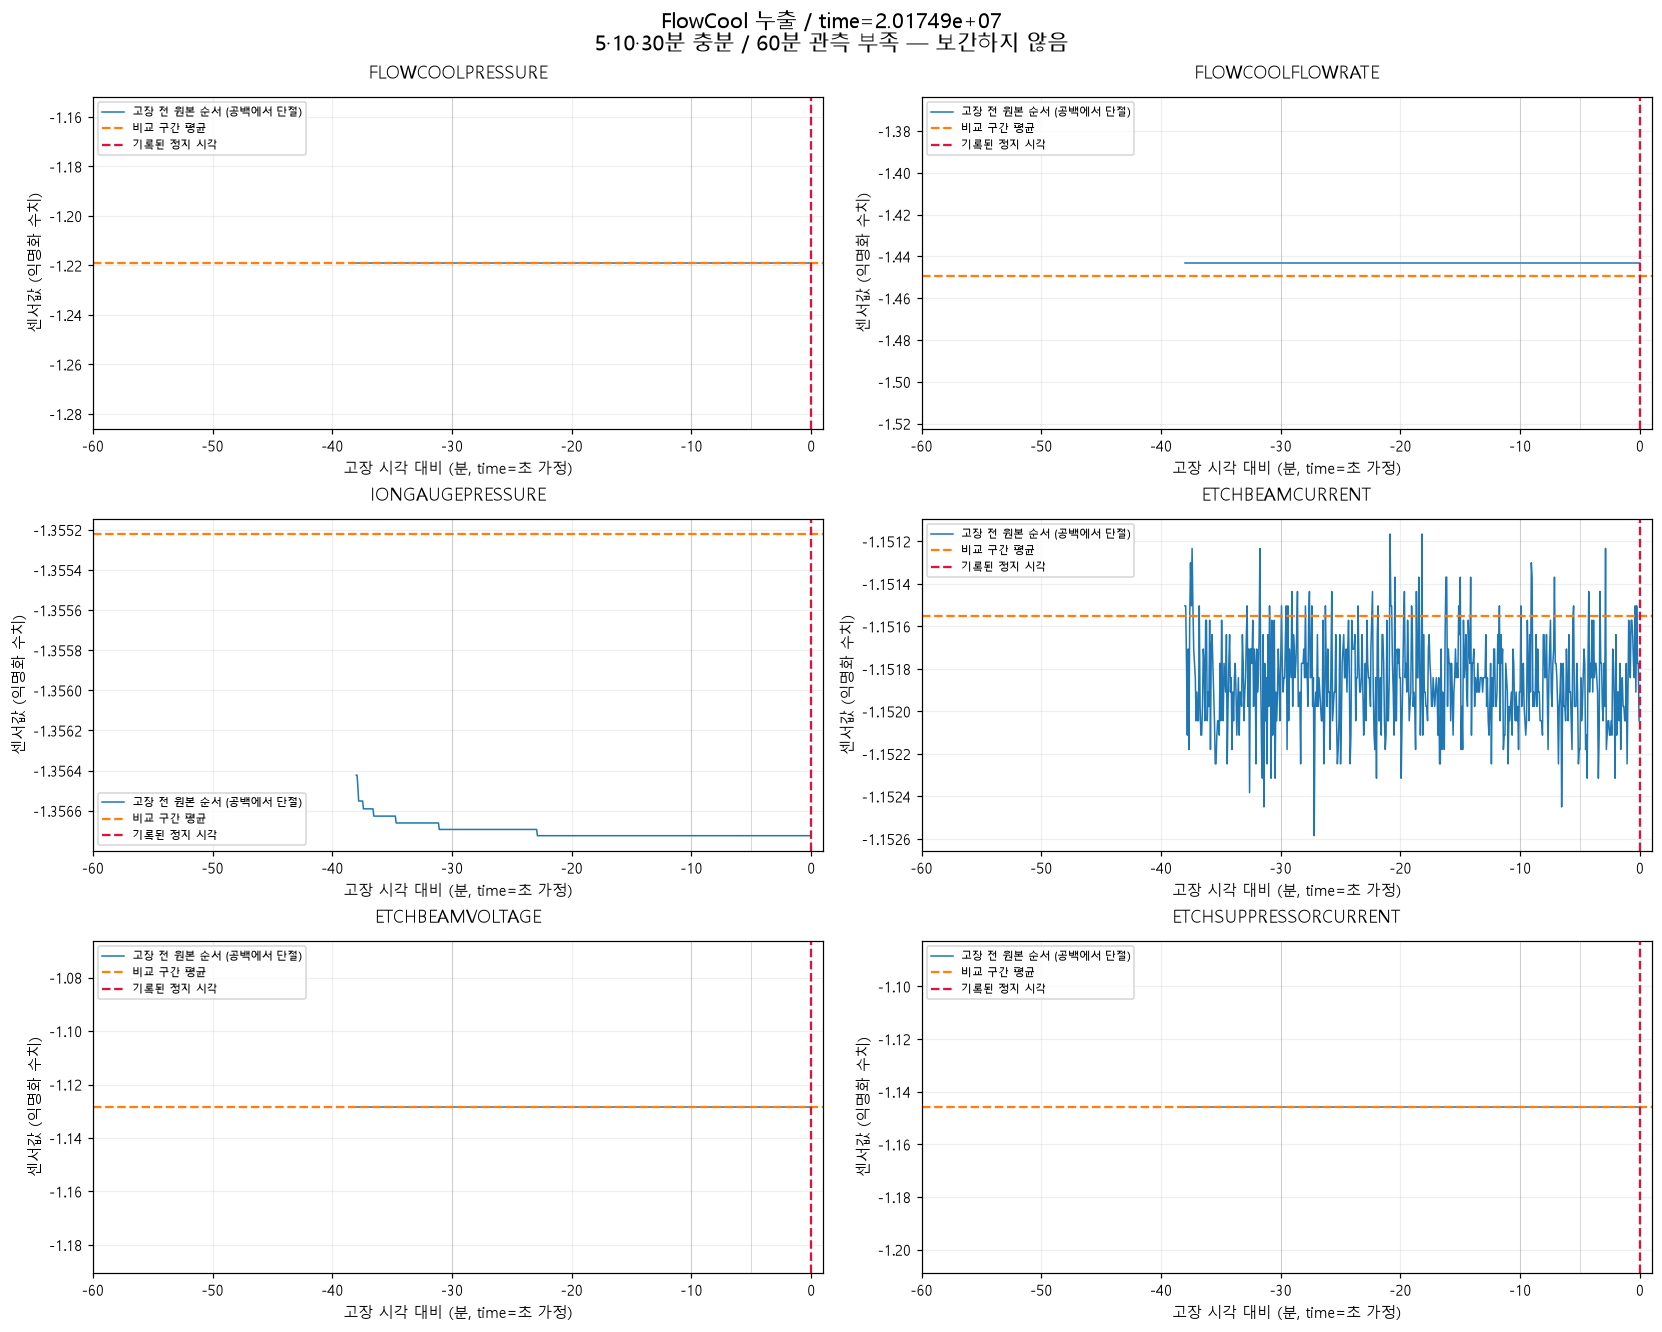

,앞쪽 관측 평균,마지막 5분 평균
FLOWCOOLPRESSURE,-1.218926,-1.218926
FLOWCOOLFLOWRATE,-1.443059,-1.443059
IONGAUGEPRESSURE,-1.356697,-1.356724
ETCHBEAMCURRENT,-1.151856,-1.151879
ETCHBEAMVOLTAGE,-1.128402,-1.128402
ETCHSUPPRESSORCURRENT,-1.145790,-1.145790


누출 보조 사례의 60분 윈도는 약 63.3%만 관측되어 충분하지 않습니다. 가동 비교 후보의 평균 차이는 공정·시간 차이도 포함합니다. 이 표와 시계열만으로 정상/고장 구분 능력이나 전조의 일반성을 주장하지 않습니다.

In [7]:
secondary=detail["secondary_event"]
active=pd.read_json(OUT/"active_control.json")
if secondary is not None:
    secondary_pre=pd.read_json(OUT/"secondary_pre.json")
    display(pd.DataFrame(secondary["windows"]))
    display(secondary_pre.groupby(["recipe","stage"]).size().rename("보조 고장 전 행 수").to_frame())
    display(pd.DataFrame([detail["active_control"]]))
    if len(active):
        display(active.groupby(["recipe","stage"]).size().rename("가동 비교 후보 행 수").to_frame())
        display(pd.DataFrame({"보조 고장 전 평균":secondary_pre[SENSORS].mean(),"가동 비교 후보 평균":active[SENSORS].mean()}))
    plots.event_plot(secondary_pre,secondary,active,name="secondary_pre_event",note="5·10·30분 충분 / 60분 관측 부족 — 보간하지 않음")
    early=secondary_pre[secondary_pre.time<secondary["time"]-300]
    late=secondary_pre[secondary_pre.time>=secondary["time"]-300]
    display(pd.DataFrame({"앞쪽 관측 평균":early[SENSORS].mean(),"마지막 5분 평균":late[SENSORS].mean()}))
    display(Markdown("누출 보조 사례의 60분 윈도는 약 63.3%만 관측되어 충분하지 않습니다. 가동 비교 후보의 평균 차이는 공정·시간 차이도 포함합니다. 이 표와 시계열만으로 정상/고장 구분 능력이나 전조의 일반성을 주장하지 않습니다."))
else:
    display(Markdown("조건을 만족하는 가동 보조 사례가 없어 보조 비교는 미실행입니다."))

## TTF 구조·결측 의미·Fault 대조

TTF 컬럼 3개를 전 파일에서 청크로 읽고, 각 행의 시각에서 다음 동일 유형 이벤트까지의 차이와 비교합니다. 센서/TTF 시간열은 중복 및 순서를 포함한 digest가 전 파일에서 동일한지 별도로 검증합니다. digest 일치는 행 단위 읽기가 가능하다는 품질 증거이지만 조인 기준은 검증한 장비·시각입니다.

공식 설명은 TTF의 null을 특정 예측 범위 내 이벤트가 없는 경우로 설명하지만, 그 범위와 관측 종료 검열을 숫자로 명시하지 않습니다. 아래 실제 기록에서 **제공된 fault 이력 내 미래 동일 유형 이벤트가 없는 경우**와 결측이 일치하는지 확인합니다. 정상으로 자동 치환하지 않습니다.

In [8]:
cols=["rows","missing","finite","matches_next_fault","mismatch","missing_with_future_fault","missing_without_future_fault","no_future_fault_finite","positive_300","positive_600","positive_1800"]
display(ttf.groupby("column")[cols].sum())
print("음수 TTF 수:",ttf.negative.sum())
display(ttf[ttf.mismatch>0])
display(pd.DataFrame([{k:v for k,v in a.items() if k!="examples"} for a in tag_audit]))
for a in tag_audit:display(pd.DataFrame(a["examples"]))
display(Markdown("실제 기록에서 결측 TTF는 모두 제공된 동일 유형의 미래 fault가 없는 구간에 있습니다. 관측 종료 이후의 상태는 알 수 없으므로 영구 정상이라는 뜻이 아닙니다. 03M02의 고압 TTF는 `[NoWaferID]` 이벤트를 포함하면 3,489행이 불일치하고, 해당 태그 이벤트를 제외하면 불일치가 0행입니다. 고압의 원본 341행/고유 333건과 태그 제외 원본 340행/고유 332건을 구분해야 합니다. 태그 이력은 삭제하지 않습니다."))

,rows,missing,finite,matches_next_fault,mismatch,missing_with_future_fault,missing_without_future_fault,no_future_fault_finite,positive_300,positive_600,positive_1800
column,,,,,,,,,,,
TTF_FlowCool Pressure Dropped Below Limit,82189440,20165908,62023532,62023532,0,0,20165908,0,19395,41095,139415
TTF_Flowcool Pressure Too High Check Flowcool Pump,82189440,26188226,56001214,55997725,3489,0,26188226,0,6284,12409,36207
TTF_Flowcool leak,82189440,44066194,38123246,38123246,0,0,44066194,0,5132,10438,31997


음수 TTF 수: 0


,Tool,column,rows,missing,finite,negative,expected_available,matches_next_fault,mismatch,no_future_fault_finite,missing_with_future_fault,missing_without_future_fault,min,max,max_abs_error,positive_300,positive_600,positive_1800,time_min,time_max,time_reversals,adjacent_duplicates
16,03M02,TTF_Flowcool Pressure Too High Check Flowcool ...,5060498,6647,5053851,0,5053851,5050362,3489,0,0,6647,0.0,8022438.0,4022.0,690,1420,4917,3284714.0,44029722.0,0,1168


,Tool,tagged_time,rows,mismatch_including_tag,mismatch_excluding_tag
0,03M02,25467346.0,5060498,3489,0


,time,ttf_actual,expected_including_tag,ttf_implied_event_time
0,25452828.0,18540.0,14518.0,25471368.0
1,25452832.0,18536.0,14514.0,25471368.0
2,25452836.0,18532.0,14510.0,25471368.0
3,25452840.0,18528.0,14506.0,25471368.0
4,25452844.0,18524.0,14502.0,25471368.0


실제 기록에서 결측 TTF는 모두 제공된 동일 유형의 미래 fault가 없는 구간에 있습니다. 관측 종료 이후의 상태는 알 수 없으므로 영구 정상이라는 뜻이 아닙니다. 03M02의 고압 TTF는 `[NoWaferID]` 이벤트를 포함하면 3,489행이 불일치하고, 해당 태그 이벤트를 제외하면 불일치가 0행입니다. 고압의 원본 341행/고유 333건과 태그 제외 원본 340행/고유 332건을 구분해야 합니다. 태그 이력은 삭제하지 않습니다.

## 5·10·30분 이내 라벨 정의 가능성

조건부 타깃은 `0 < 다음 고장 시각 - t <= H`, H=300/600/1800 원시단위입니다. 고장 시각 자체와 이력/TTF가 모순되는 행은 제외합니다. `[NoWaferID]` 제외 정책을 먼저 명시해야 합니다. 물리 분 단위는 time=초 가정에 한정됩니다.

양성은 확인된 미래 이벤트를 이용해 정의할 수 있습니다. 음성은 예측 구간 전체의 추적 관측 및 이벤트 기록 완전성이 검증되어야 합니다. `horizon_labels`는 그 검증을 전달하지 않으면 음성을 임의 생성하지 않고 NA를 유지합니다. 아래는 실제 대표 고장 전 구간에 적용한 **라벨 정의 점검**이며 학습 데이터셋이나 예측 결과가 아닙니다.

In [9]:
target_fault=event["fault_name"]
target_times=faults.loc[(faults.Tool==detail["Tool"])&(faults.fault_raw==target_fault),"time"].to_numpy()
label_counts=[]
for h in (300,600,1800):
    labels=horizon_labels(pre.time.to_numpy(),target_times,pre.time.max(),h)
    label_counts.append({"원시시간 구간":h,"분 (초 가정)":h//60,"양성":int((labels==1).sum()),"음성":int((labels==0).sum()),"미확인":int(labels.isna().sum())})
display(pd.DataFrame(label_counts))
display(Markdown("완전성 미검증 행은 NA로 남겼으므로 음성 수 0은 정상 구간이 없다는 뜻이 아닙니다. TTF가 유한하고 H보다 큰 경우에도 시간 단위·이벤트 정의를 검증한 뒤 음성 후보로 쓸 수 있습니다. 결측 TTF, 관측 종료, 내부 공백 및 태그 관련 불일치 구간은 별도 검열/제외 정책이 필요합니다."))

,원시시간 구간,분 (초 가정),양성,음성,미확인
0,300,5,75,0,825
1,600,10,150,0,750
2,1800,30,450,0,450


완전성 미검증 행은 NA로 남겼으므로 음성 수 0은 정상 구간이 없다는 뜻이 아닙니다. TTF가 유한하고 H보다 큰 경우에도 시간 단위·이벤트 정의를 검증한 뒤 음성 후보로 쓸 수 있습니다. 결측 TTF, 관측 종료, 내부 공백 및 태그 관련 불일치 구간은 별도 검열/제외 정책이 필요합니다.

## 모델 구축 전에 필요한 처리

1. 시간 단위와 고장·태그 포함 정책을 확정하고, 관측 공백·정지 상태·검열을 구분합니다.
2. 동시각 기록을 원본 행 ID와 함께 보존하고 공정 차이를 확인한 뒤 집계 정책을 정합니다. 임의 중복 삭제와 긴 공백 보간은 하지 않습니다.
3. 장비/Recipe/Stage별 기준을 검토하고 과거 방향 윈도로 특징을 만듭니다. TTF/fault는 정답에만 사용합니다. ACTUALSTEPDURATION 등은 관측 가능 시점 확인 전 특징으로 쓰지 않습니다.
4. 장비 단위 외부 검증과 시간 순서 내부 검증을 설계합니다. 중첩 윈도·동일 이벤트가 경계를 넘지 않도록 윈도/예측 구간에 맞는 간격을 둡니다. 기존 test는 학습 장비의 후속 구간입니다.
5. 이벤트 매칭·경보 병합·최소 Lead Time·정상 운전 노출시간을 정의하고 F1-score, Event Recall, 시간당 False Alarm Rate, Lead Time 분포를 함께 평가합니다.

**미검증:** 물리 단위, 실제 이상 시작 시각, 고장 이력의 완전성, 전체 센서 24컬럼의 품질, 대표 장비 이외의 상세 분포·고장 전 패턴, 통계적 일반성. 실제 모델 학습 및 성능 평가는 수행하지 않았습니다.